# 5. Supervised Learning: Predicting Hospitalization or Death

**Input:** the modeling inputs from notebook 4 (`data/features/`).
**Output:** model comparison, in-depth evaluation of the best model, and the scoring artifact used by notebook 7:
tables in `reports/tables/`, figures in `reports/figures/`, model in `models/`.

**Task:** for one FAERS case, predict `y` = hospitalization or death, from the patient, the report and the suspect
drugs. Reaction terms and the `expedited` flag are not features: they restate the target (notebook 3, findings 9-10).

| Section | What it answers |
|---|---|
| 1 | Load the features and the time split |
| 2 | Four model families, and why |
| 3 | Hyperparameter tuning on the validation quarters |
| 4 | 5-fold cross-validation: mean and standard deviation per family |
| 5 | Final models on validation and the held-out test quarters |
| 6 | Calibration of the best model |
| 7 | Feature importance and ablation |
| 8 | Sensitivity: hyperparameters, drug vocabulary size, training size |
| 9 | Trade-offs: precision vs recall, speed vs accuracy, drift over time |
| 10 | Failure analysis |
| 11 | Save the scoring model |

This notebook builds on Che-Yu Liu's first gradient-boosting notebook (`archive/original_notebooks/`).

## 1. Setup and load

Notebook 4 already did the work that must be fit on training data only: the top-400 ingredient list, the
country levels, the scaler and the one-hot levels. We reuse its matrices so every model sees exactly the same
440 columns.

| Split | Quarters | Rows | Use here |
|---|---|---|---|
| train sample | 2020Q1-2024Q3 | 1,000,000 (stratified sample) | fit, cross-validation |
| val | 2025Q1-2025Q2 | ~626k | tuning, threshold, calibration |
| test | 2025Q3-2026Q2 | ~1.47M | touched once, in section 5 onward |

The tree models need dense input. 1M x 440 float32 is 1.8 GB; validation and test are scored in chunks.

In [1]:
from __future__ import annotations

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import scipy.sparse as sp
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import BernoulliNB

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
FEATURES_DIR = PROJECT_ROOT / "data" / "features"
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
MODEL_DIR = PROJECT_ROOT / "models"
for folder in (FIG_DIR, TABLE_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

X = {s: sp.load_npz(FEATURES_DIR / f"X_{s}.npz").tocsr() for s in ["train", "val", "test"]}
y = {s: np.load(FEATURES_DIR / f"y_{s}.npy").astype(int) for s in ["train", "val", "test"]}
ids = {s: np.load(FEATURES_DIR / f"ids_{s}.npy", allow_pickle=True) for s in ["train", "val", "test"]}
feature_names = json.loads((FEATURES_DIR / "feature_names.json").read_text())
baseline_metrics = json.loads((FEATURES_DIR / "baseline_metrics.json").read_text())

for s in X:
    print(f"{s:5s}: {X[s].shape[0]:>9,} rows x {X[s].shape[1]} cols, positive rate {y[s].mean():.3f}")

X_train = X["train"].toarray().astype(np.float32)  # dense copy for the tree models
print(f"dense train matrix: {X_train.nbytes / 1e9:.2f} GB")


def save_fig(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def predict(model, M, cols=None, chunk: int = 200_000) -> np.ndarray:
    """P(serious) for a sparse matrix, scored in dense chunks to keep memory flat."""
    out = []
    for start in range(0, M.shape[0], chunk):
        part = M[start:start + chunk]
        part = part.toarray() if sp.issparse(part) else part
        if cols is not None:
            part = part[:, cols]
        out.append(model.predict_proba(part.astype(np.float32))[:, 1])
    return np.concatenate(out)


def scores(y_true, p) -> dict:
    return {"avg_precision": average_precision_score(y_true, p), "roc_auc": roc_auc_score(y_true, p),
            "brier": brier_score_loss(y_true, p)}

train: 1,000,000 rows x 440 cols, positive rate 0.258
val  :   626,361 rows x 440 cols, positive rate 0.260
test : 1,471,699 rows x 440 cols, positive rate 0.262


dense train matrix: 1.76 GB


**Feature groups.** The 440 columns come from 15 original features. For importance and ablation we treat each
original feature (all its one-hot columns together) and the 400 drug flags as units.

In [2]:
CAT_COLS = ["sex", "age_group", "reporter", "report_type", "country"]


def original_feature(name: str) -> str:
    if name.startswith("drug="):
        return "drug flags (top 400)"
    for col in CAT_COLS:
        if name.startswith(f"cat__{col}_"):
            return col
    return name.split("__", 1)[1]


FEATURE_OF = np.array([original_feature(n) for n in feature_names])
GROUPS = {
    "patient": ["age_years", "age_missing", "age_group", "sex", "weight_kg", "weight_missing"],
    "report": ["reporter", "report_type", "country", "is_us"],
    "drug counts": ["n_drugs", "n_suspect_ingredients", "n_other_ingredients"],
    "drug identity": ["drug flags (top 400)"],
}
group_cols = {g: np.flatnonzero(np.isin(FEATURE_OF, members)) for g, members in GROUPS.items()}
assert sum(len(c) for c in group_cols.values()) == len(feature_names)
display(pd.Series({g: len(c) for g, c in group_cols.items()}, name="columns").to_frame().T)

,patient,report,drug counts,drug identity
columns,14,23,3,400


## 2. Model families

Four families with different mechanisms, plus the prior as a floor:

| Family | Model | Mechanism | Why it fits this problem |
|---|---|---|---|
| Linear, discriminative | Logistic regression | one weight per column, log-odds are additive | interpretable baseline from notebook 4; coefficients are readable as drug or reporter effects |
| Probabilistic, generative | Bernoulli naive Bayes | P(features given class), features assumed independent | very fast; tests whether binary presence/absence of drugs and categories is enough |
| Bagged trees | Random forest | average of deep, decorrelated trees | captures interactions (e.g. drug x age) without tuning-sensitive boosting |
| Boosted trees | Histogram gradient boosting | trees added one at a time to fix the previous errors | usually the strongest on tabular data with mixed types and interactions |

Naive Bayes binarizes each column at 0: drug flags and one-hot columns stay as they are, scaled numbers become
"above / below the training mean". Trees are not affected by the scaling done in notebook 4.

**Metric.** Average precision (area under the precision-recall curve, PR-AUC) is the primary metric: positives
are 26% of cases, and a reviewer cares about how pure the top of the ranked list is. ROC AUC is reported for
comparison with the literature, and the Brier score measures whether the probabilities are trustworthy.

## 3. Hyperparameter tuning

Each family is tuned on a 300,000-row stratified subsample of the training sample and scored on the
**validation quarters** (2025Q1-Q2). Tuning on later quarters picks settings that hold up over time, which a
random split would not test. The test quarters stay untouched.

In [3]:
TUNE_SIZE = 300_000
tune_rows = np.sort(rng.choice(len(y["train"]), TUNE_SIZE, replace=False))
X_tune, y_tune = X_train[tune_rows], y["train"][tune_rows]

search_space = {
    "logistic regression": [LogisticRegression(C=c, max_iter=1000) for c in (0.01, 0.1, 1.0, 10.0)],
    "naive Bayes": [BernoulliNB(alpha=a, binarize=0.0) for a in (0.1, 1.0, 10.0)],
    "random forest": [
        RandomForestClassifier(n_estimators=200, max_features=mf, min_samples_leaf=leaf, max_samples=0.5,
                               n_jobs=-1, random_state=RANDOM_STATE)
        for mf in ("sqrt", 0.1) for leaf in (5, 25, 100)
    ],
    "gradient boosting": [
        HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=iters,
                                       l2_regularization=1.0, min_samples_leaf=50, early_stopping=False,
                                       random_state=RANDOM_STATE)
        for lr, leaves, iters in [(0.05, 31, 300), (0.1, 31, 300), (0.1, 63, 300), (0.1, 127, 300),
                                  (0.05, 63, 600), (0.2, 63, 300), (0.1, 255, 300)]
    ],
}
PARAM_KEYS = {"logistic regression": ["C"], "naive Bayes": ["alpha"],
              "random forest": ["max_features", "min_samples_leaf"],
              "gradient boosting": ["learning_rate", "max_leaf_nodes", "max_iter"]}

tuning_rows, best = [], {}
for family, candidates in search_space.items():
    for model in candidates:
        start = time.time()
        model.fit(X_tune, y_tune)
        fit_s = time.time() - start
        p_val = predict(model, X["val"])
        params = {k: model.get_params()[k] for k in PARAM_KEYS[family]}
        row = {"family": family, "params": str(params), **scores(y["val"], p_val), "fit_seconds": fit_s}
        tuning_rows.append(row)
        if family not in best or row["avg_precision"] > best[family][1]:
            best[family] = (clone(model), row["avg_precision"])
        print(f"{family:20s} {params}  val AP {row['avg_precision']:.4f}  ({fit_s:.0f}s)")

tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(TABLE_DIR / "supervised_tuning.csv", index=False)
print("\nbest setting per family (validation AP):")
display(tuning.loc[tuning.groupby("family")["avg_precision"].idxmax()].round(4))

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/suvidhinikhil/Data scien

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science

logistic regression  {'C': 0.01}  val AP 0.5444  (51s)


...

gradient boosting    {'learning_rate': 0.1, 'max_leaf_nodes': 127, 'max_iter': 300}  val AP 0.6250  (209s)


gradient boosting    {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'max_iter': 600}  val AP 0.6214  (191s)


gradient boosting    {'learning_rate': 0.2, 'max_leaf_nodes': 63, 'max_iter': 300}  val AP 0.6216  (148s)


gradient boosting    {'learning_rate': 0.1, 'max_leaf_nodes': 255, 'max_iter': 300}  val AP 0.6236  (651s)

best setting per family (validation AP):


,family,params,avg_precision,roc_auc,brier,fit_seconds
16,gradient boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 127, ...",0.6250,0.8301,0.1399,209.1696
3,logistic regression,{'C': 10.0},0.5508,0.7984,0.1520,15.0277
4,naive Bayes,{'alpha': 0.1},0.5210,0.7854,0.2081,2.2468
10,random forest,"{'max_features': 0.1, 'min_samples_leaf': 5}",0.6083,0.8210,0.1434,243.1108


## 4. Cross-validation: 5 folds per family

One train/validation split can flatter one model by chance, so the tuned settings are compared with 5-fold
stratified cross-validation inside the training sample. Folds are drawn from a 250,000-row subsample to keep
the random forest affordable; every family sees the same folds. We report the mean and standard deviation over
the folds.

In [4]:
CV_SIZE = 250_000
cv_rows = np.sort(rng.choice(len(y["train"]), CV_SIZE, replace=False))
X_cv, y_cv = X_train[cv_rows], y["train"][cv_rows]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_models = {"prior": DummyClassifier(strategy="prior"), **{f: m for f, (m, _) in best.items()}}
cv_records = []
for family, model in cv_models.items():
    for fold, (tr, te) in enumerate(folds.split(X_cv, y_cv)):
        fitted = clone(model)
        start = time.time()
        fitted.fit(X_cv[tr], y_cv[tr])
        fit_s = time.time() - start
        p = fitted.predict_proba(X_cv[te])[:, 1]
        cv_records.append({"family": family, "fold": fold, **scores(y_cv[te], p), "fit_seconds": fit_s})
    print(f"{family}: done")

cv_results = pd.DataFrame(cv_records)
cv_summary = cv_results.groupby("family", sort=False)[["avg_precision", "roc_auc", "brier", "fit_seconds"]].agg(["mean", "std"])
cv_summary.to_csv(TABLE_DIR / "supervised_cv_summary.csv")
display(cv_summary.round(4))

prior: done


/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/suvidhinikhil/Data scien

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in m

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in m

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in m

...

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


naive Bayes: done


random forest: done


gradient boosting: done


avg_precision         roc_auc           brier         fit_seconds          
                             mean     std    mean     std    mean     std        mean       std
family                                                                                         
prior                      0.2584  0.0000  0.5000  0.0000  0.1916  0.0000      0.0268    0.0104
logistic regression        0.5674  0.0031  0.8016  0.0030  0.1493  0.0008      5.2701    0.3182
naive Bayes                0.5162  0.0026  0.7771  0.0020  0.2073  0.0015      0.5158    0.1610
random forest              0.6239  0.0030  0.8229  0.0022  0.1415  0.0006     25.8040    1.3976
gradient boosting          0.6447  0.0038  0.8343  0.0028  0.1364  0.0010    187.0078  121.4654

## 5. Final models: validation and test

Each family's best setting is refit on the full 1,000,000-row training sample. The decision threshold is chosen
on **validation** (the one that maximizes F1) and then applied unchanged to **test**: choosing it on test would
overstate precision and recall.

In [5]:
def best_f1_threshold(y_true, p) -> float:
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def threshold_metrics(y_true, p, threshold) -> dict:
    pred = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {"threshold": threshold, "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / max(precision + recall, 1e-12), "alert_rate": pred.mean(),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


final_models, val_probs, test_probs, final_rows = {}, {}, {}, []
for family, (model, _) in {"prior": (DummyClassifier(strategy="prior"), None), **best}.items():
    model = clone(model)
    start = time.time()
    model.fit(X_train, y["train"])
    fit_s = time.time() - start
    start = time.time()
    val_probs[family] = predict(model, X["val"])
    test_probs[family] = predict(model, X["test"])
    score_s = time.time() - start
    threshold = best_f1_threshold(y["val"], val_probs[family]) if family != "prior" else 0.5
    final_models[family] = model
    for split, p in (("val", val_probs[family]), ("test", test_probs[family])):
        final_rows.append({"family": family, "split": split, **scores(y[split], p),
                           **threshold_metrics(y[split], p, threshold), "fit_seconds": fit_s,
                           "score_seconds_val_test": score_s})
    print(f"{family:20s} fit {fit_s:5.0f}s   test AP {final_rows[-1]['avg_precision']:.4f}")

final_results = pd.DataFrame(final_rows)
final_results.to_csv(TABLE_DIR / "supervised_final_results.csv", index=False)
cols = ["family", "split", "avg_precision", "roc_auc", "brier", "threshold", "precision", "recall", "f1",
        "alert_rate", "fit_seconds"]
display(final_results[cols].round(4))
print("notebook 4 baseline (logreg, all features, val):", baseline_metrics["logreg, all features"])

BEST = final_results.query("split == 'val'").set_index("family")["avg_precision"].idxmax()
print(f"\nbest family on validation AP: {BEST}")

prior                fit     0s   test AP 0.2615


/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/suvidhinikhil/Data scien

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science

/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science projects/Milestone 2 projects/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/suvidhinikhil/Data science

...

naive Bayes          fit     2s   test AP 0.5082


random forest        fit   190s   test AP 0.5875


gradient boosting    fit   265s   test AP 0.6017


,family,split,avg_precision,roc_auc,brier,threshold,precision,recall,f1,alert_rate,fit_seconds
0,prior,val,0.2599,0.5000,0.1924,0.5000,0.0000,0.0000,0.0000,0.0000,0.0262
1,prior,test,0.2615,0.5000,0.1931,0.5000,0.0000,0.0000,0.0000,0.0000,0.0262
2,logistic regression,val,0.5508,0.7983,0.1520,0.2533,0.4738,0.7553,0.5823,0.4143,20.6334
3,logistic regression,test,0.5340,0.7879,0.1557,0.2533,0.4576,0.7674,0.5733,0.4386,20.6334
4,naive Bayes,val,0.5207,0.7851,0.2083,0.1636,0.4578,0.7694,0.5740,0.4368,2.4155
5,naive Bayes,test,0.5082,0.7783,0.2165,0.1636,0.4467,0.7796,0.5679,0.4564,2.4155
6,random forest,val,0.6271,0.8291,0.1401,0.3184,0.5135,0.7481,0.6090,0.3786,190.4229
7,random forest,test,0.5875,0.8111,0.1473,0.3184,0.4851,0.7493,0.5889,0.4039,190.4229
8,gradient boosting,val,0.6351,0.8342,0.1381,0.3096,0.5277,0.7356,0.6145,0.3623,265.1123
9,gradient boosting,test,0.6017,0.8175,0.1449,0.3096,0.4995,0.7381,0.5958,0.3864,265.1123


notebook 4 baseline (logreg, all features, val): {'n_features': 440, 'val_roc_auc': 0.7985, 'val_avg_precision': 0.5507}

best family on validation AP: gradient boosting


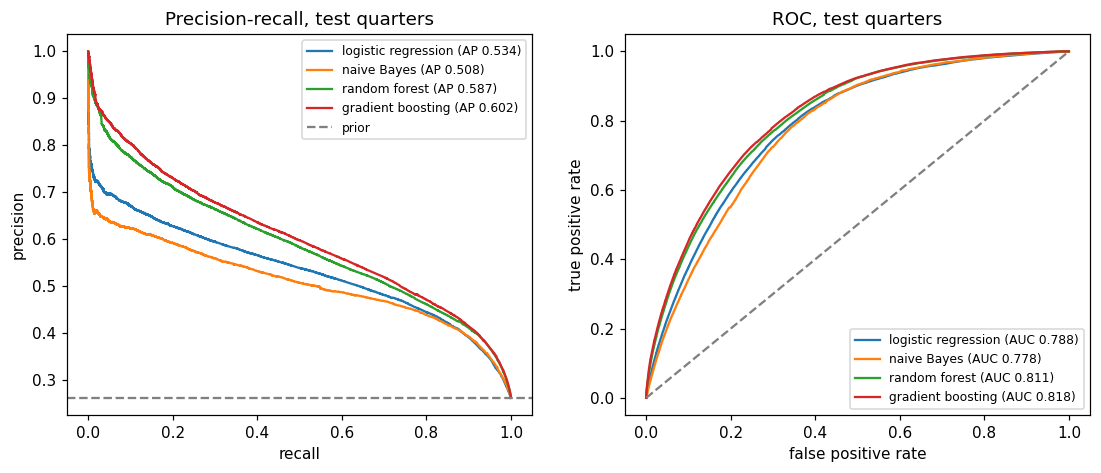

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for family in final_models:
    if family == "prior":
        continue
    p = test_probs[family]
    precision, recall, _ = precision_recall_curve(y["test"], p)
    fpr, tpr, _ = roc_curve(y["test"], p)
    axes[0].plot(recall, precision, label=f"{family} (AP {average_precision_score(y['test'], p):.3f})")
    axes[1].plot(fpr, tpr, label=f"{family} (AUC {roc_auc_score(y['test'], p):.3f})")
axes[0].axhline(y["test"].mean(), color="grey", ls="--", label="prior")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall, test quarters")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC, test quarters")
for ax in axes:
    ax.legend(fontsize=8)
save_fig(fig, "sup_pr_roc_test")
plt.show()

## 6. Calibration

A triage queue sorts by score, which needs only a good ranking. But if the score is shown to a reviewer as
"38% chance", it should mean 38%. Isotonic regression is fit on the **validation** predictions of the best
model and applied to test. It keeps the order of cases, but its step function ties some scores, so AP can move slightly.

**Result:** the raw boosting probabilities are already well calibrated (test Brier 0.1449). Isotonic calibration barely changes the Brier score (0.1448) and lowers AP a little (0.596 vs 0.602) because of the ties. The pipeline therefore ranks by the raw score and shows the calibrated value only as the displayed probability.

,avg_precision,roc_auc,brier
uncalibrated,0.6017,0.8175,0.1449
isotonic (fit on val),0.5963,0.8174,0.1448


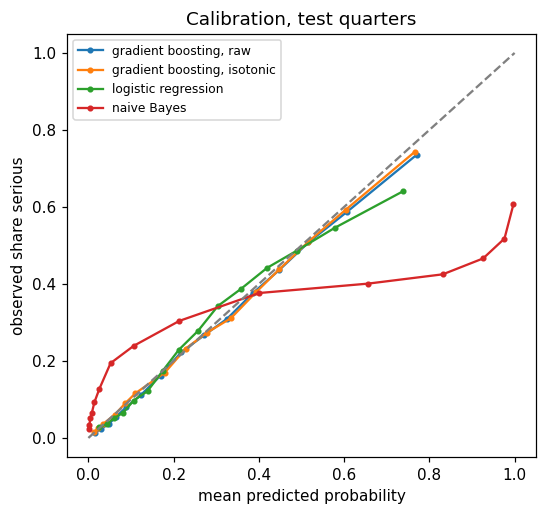

In [7]:
calibrator = IsotonicRegression(out_of_bounds="clip").fit(val_probs[BEST], y["val"])
p_test_cal = calibrator.predict(test_probs[BEST])

calibration_table = pd.DataFrame({
    "uncalibrated": scores(y["test"], test_probs[BEST]),
    "isotonic (fit on val)": scores(y["test"], p_test_cal),
}).T
display(calibration_table.round(4))
calibration_table.to_csv(TABLE_DIR / "supervised_calibration.csv")

fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p in [(f"{BEST}, raw", test_probs[BEST]), (f"{BEST}, isotonic", p_test_cal),
                 ("logistic regression", test_probs["logistic regression"]), ("naive Bayes", test_probs["naive Bayes"])]:
    frac_pos, mean_pred = calibration_curve(y["test"], p, n_bins=15, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=3, label=label)
ax.plot([0, 1], [0, 1], color="grey", ls="--")
ax.set(xlabel="mean predicted probability", ylabel="observed share serious", title="Calibration, test quarters")
ax.legend(fontsize=8)
save_fig(fig, "sup_calibration")
plt.show()

## 7. Feature importance and ablation (best model)

**Permutation importance:** shuffle one original feature (all its columns together, so a one-hot block stays
valid) on 150,000 validation rows and measure the drop in AP. Three repeats. The 400 drug flags are shuffled
together as one unit and, separately, one at a time for the top drugs.

**Ablation:** retrain without each feature group and see how much AP is lost; also train on each group alone.
Retraining is the stronger test, because correlated features can stand in for a removed one.

In [8]:
best_model = final_models[BEST]
imp_rows = np.sort(rng.choice(len(y["val"]), 150_000, replace=False))
X_imp = X["val"][imp_rows].toarray().astype(np.float32)
y_imp = y["val"][imp_rows]
base_ap = average_precision_score(y_imp, best_model.predict_proba(X_imp)[:, 1])


def permutation_drop(cols, repeats: int = 3) -> tuple[float, float]:
    drops = []
    for r in range(repeats):
        shuffled = X_imp.copy()
        order = np.random.default_rng(r).permutation(len(shuffled))
        shuffled[:, cols] = shuffled[order][:, cols]
        drops.append(base_ap - average_precision_score(y_imp, best_model.predict_proba(shuffled)[:, 1]))
    return float(np.mean(drops)), float(np.std(drops))


units = {name: np.flatnonzero(FEATURE_OF == name) for name in pd.unique(FEATURE_OF)}
perm = pd.DataFrame([(name, *permutation_drop(cols)) for name, cols in units.items()],
                    columns=["feature", "ap_drop_mean", "ap_drop_std"]).sort_values("ap_drop_mean", ascending=False)

drug_cols = group_cols["drug identity"]
drug_presence = np.asarray(X_imp[:, drug_cols].sum(axis=0)).ravel()
top_drug_cols = drug_cols[np.argsort(-drug_presence)[:60]]  # the 60 most common drugs in this sample
drug_perm = pd.DataFrame([(feature_names[c].removeprefix("drug="), *permutation_drop([c], repeats=2))
                          for c in top_drug_cols], columns=["drug", "ap_drop_mean", "ap_drop_std"])
drug_perm = drug_perm.sort_values("ap_drop_mean", ascending=False)

perm.to_csv(TABLE_DIR / "supervised_permutation_importance.csv", index=False)
drug_perm.to_csv(TABLE_DIR / "supervised_permutation_importance_drugs.csv", index=False)
print(f"baseline AP on the importance sample: {base_ap:.4f}")
display(perm.round(4))
display(drug_perm.head(15).round(4))

baseline AP on the importance sample: 0.6330


,feature,ap_drop_mean,ap_drop_std
13,drug flags (top 400),0.1584,0.0011
7,is_us,0.0719,0.0007
10,reporter,0.0458,0.0002
11,report_type,0.0437,0.0004
2,n_drugs,0.0247,0.0007
12,country,0.0143,0.0005
0,age_years,0.0129,0.0004
3,n_suspect_ingredients,0.0123,0.0002
5,age_missing,0.0123,0.0002
8,sex,0.0094,0.0001


,drug,ap_drop_mean,ap_drop_std
0,DUPILUMAB,0.0128,0.0004
4,ACETAMINOPHEN,0.0082,0.0002
28,CLOZAPINE,0.0037,0.0001
27,TREPROSTINIL,0.0033,0.0000
26,LEUPROLIDE,0.0024,0.0001
22,CABOZANTINIB,0.0019,0.0000
50,METFORMIN,0.0018,0.0001
15,SOMATROPIN,0.0014,0.0001
1,TIRZEPATIDE,0.0012,0.0001
51,GOLIMUMAB,0.0011,0.0000


In [9]:
ABL_SIZE = 500_000
abl_rows = np.sort(rng.choice(len(y["train"]), ABL_SIZE, replace=False))
X_abl, y_abl = X_train[abl_rows], y["train"][abl_rows]
all_cols = np.arange(len(feature_names))


def fit_and_score(cols, params=None, X_fit=X_abl, y_fit=y_abl) -> float:
    model = clone(best_model).set_params(**(params or {}))
    model.fit(X_fit[:, cols], y_fit)
    return average_precision_score(y["val"], predict(model, X["val"], cols=cols))


ablation_rows = [("all features", len(all_cols), fit_and_score(all_cols))]
for group, cols in group_cols.items():
    keep = np.setdiff1d(all_cols, cols)
    ablation_rows.append((f"without {group}", len(keep), fit_and_score(keep)))
for group, cols in group_cols.items():
    ablation_rows.append((f"only {group}", len(cols), fit_and_score(cols)))
    print("done:", group)

ablation = pd.DataFrame(ablation_rows, columns=["variant", "n_columns", "val_avg_precision"])
ablation["change_vs_all"] = ablation["val_avg_precision"] - ablation.loc[0, "val_avg_precision"]
ablation.to_csv(TABLE_DIR / "supervised_ablation.csv", index=False)
display(ablation.round(4))

done: patient


done: report


done: drug counts


done: drug identity


,variant,n_columns,val_avg_precision,change_vs_all
0,all features,440,0.6301,0.0000
1,without patient,426,0.6119,-0.0182
2,without report,417,0.5661,-0.0640
3,without drug counts,437,0.6223,-0.0078
4,without drug identity,40,0.5629,-0.0673
5,only patient,14,0.3730,-0.2571
6,only report,23,0.4639,-0.1663
7,only drug counts,3,0.4047,-0.2254
8,only drug identity,400,0.4963,-0.1338


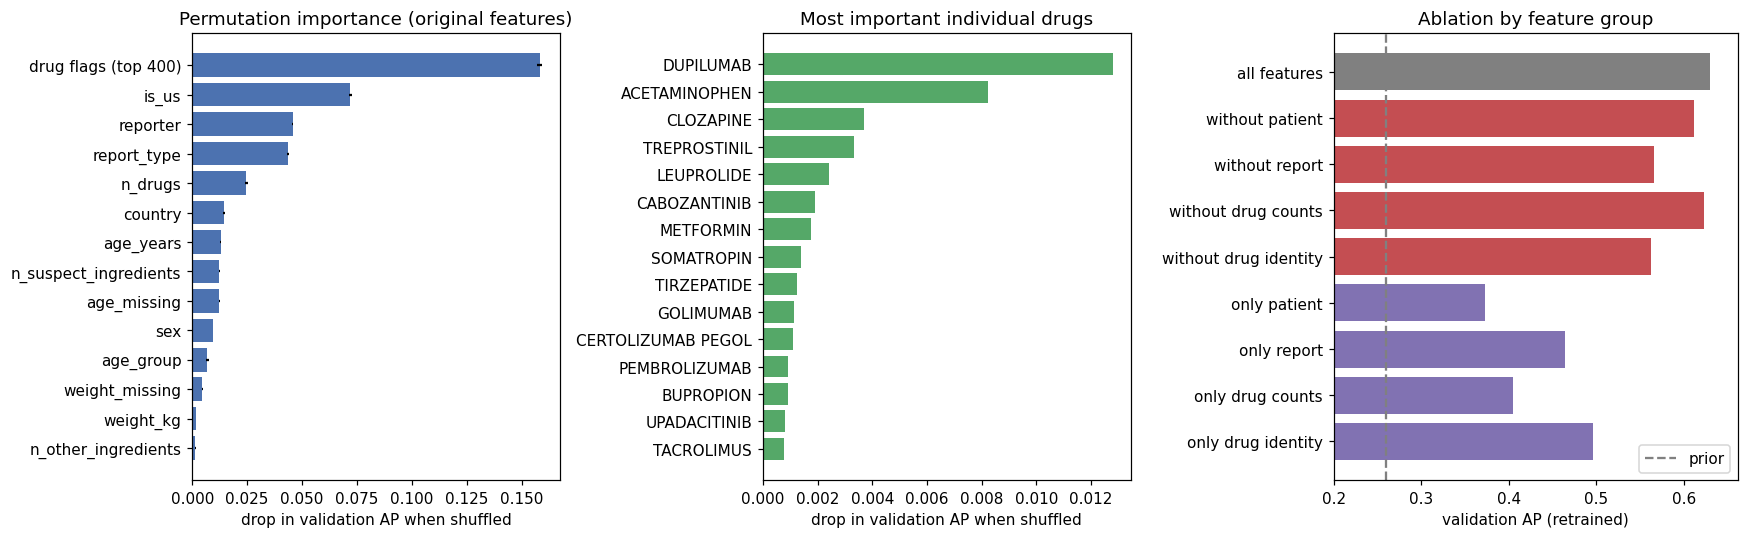

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.1]})
top_perm = perm.head(15).iloc[::-1]
axes[0].barh(top_perm["feature"], top_perm["ap_drop_mean"], xerr=top_perm["ap_drop_std"], color="#4C72B0")
axes[0].set(xlabel="drop in validation AP when shuffled", title="Permutation importance (original features)")
top_drugs_plot = drug_perm.head(15).iloc[::-1]
axes[1].barh(top_drugs_plot["drug"], top_drugs_plot["ap_drop_mean"], color="#55A868")
axes[1].set(xlabel="drop in validation AP when shuffled", title="Most important individual drugs")
abl_plot = ablation.iloc[::-1]
colors = ["#C44E52" if v.startswith("without") else "#8172B2" if v.startswith("only") else "grey"
          for v in abl_plot["variant"]]
axes[2].barh(abl_plot["variant"], abl_plot["val_avg_precision"], color=colors)
axes[2].axvline(y["val"].mean(), color="grey", ls="--", label="prior")
axes[2].set(xlabel="validation AP (retrained)", title="Ablation by feature group", xlim=(0.2, None))
axes[2].legend()
fig.tight_layout()
save_fig(fig, "sup_importance_ablation")
plt.show()

## 8. Sensitivity analysis (best model)

Three questions, each on the 500,000-row ablation sample and scored on validation:

1. **Hyperparameters:** how much does AP move with the learning rate, the number of boosting rounds and tree size?
2. **Drug vocabulary:** notebook 4 kept the 400 most common ingredients. What if we keep 0, 25, 50, 100, 200?
   The drug columns are sorted by training frequency, so "top K" is the first K drug columns.
3. **Training size:** how much would more data help?

In [11]:
sens_rows = []
if BEST == "gradient boosting":
    for lr in (0.03, 0.1, 0.3):
        for iters in (100, 300, 600):
            ap = fit_and_score(all_cols, {"learning_rate": lr, "max_iter": iters})
            sens_rows.append({"experiment": "learning rate x rounds", "learning_rate": lr, "max_iter": iters,
                              "val_avg_precision": ap})
    for leaves in (15, 31, 63, 127, 255):
        ap = fit_and_score(all_cols, {"max_leaf_nodes": leaves})
        sens_rows.append({"experiment": "tree size", "max_leaf_nodes": leaves, "val_avg_precision": ap})

non_drug_cols = np.setdiff1d(all_cols, drug_cols)
for k in (0, 25, 50, 100, 200, 400):
    cols = np.concatenate([non_drug_cols, drug_cols[:k]])
    sens_rows.append({"experiment": "drug vocabulary", "top_k_drugs": k, "val_avg_precision": fit_and_score(cols)})

for n in (10_000, 30_000, 100_000, 300_000, 1_000_000):
    rows = np.sort(rng.choice(len(y["train"]), n, replace=False)) if n < len(y["train"]) else np.arange(len(y["train"]))
    start = time.time()
    ap = fit_and_score(all_cols, X_fit=X_train[rows], y_fit=y["train"][rows])
    sens_rows.append({"experiment": "training size", "n_train": n, "val_avg_precision": ap,
                      "seconds": time.time() - start})
    print("training size", n, round(ap, 4))

seed_aps = [fit_and_score(all_cols, {"random_state": s}) for s in range(5)]
sens_rows.append({"experiment": "random seed (5 seeds)", "val_avg_precision": float(np.mean(seed_aps)),
                  "std": float(np.std(seed_aps))})

sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(TABLE_DIR / "supervised_sensitivity.csv", index=False)
display(sensitivity.round(4))

training size 10000 0.4962


training size 30000 0.5582


training size 100000 0.5993


training size 300000 0.6233


training size 1000000 0.6351


,experiment,learning_rate,max_iter,val_avg_precision,max_leaf_nodes,top_k_drugs,n_train,seconds,std
0,learning rate x rounds,0.03,100.0,0.5989,NaN,NaN,NaN,NaN,NaN
1,learning rate x rounds,0.03,300.0,0.6215,NaN,NaN,NaN,NaN,NaN
2,learning rate x rounds,0.03,600.0,0.6269,NaN,NaN,NaN,NaN,NaN
3,learning rate x rounds,0.10,100.0,0.6217,NaN,NaN,NaN,NaN,NaN
4,learning rate x rounds,0.10,300.0,0.6301,NaN,NaN,NaN,NaN,NaN
5,learning rate x rounds,0.10,600.0,0.6309,NaN,NaN,NaN,NaN,NaN
6,learning rate x rounds,0.30,100.0,0.6263,NaN,NaN,NaN,NaN,NaN
7,learning rate x rounds,0.30,300.0,0.6254,NaN,NaN,NaN,NaN,NaN
8,learning rate x rounds,0.30,600.0,0.6182,NaN,NaN,NaN,NaN,NaN
9,tree size,NaN,NaN,0.5993,15.0,NaN,NaN,NaN,NaN


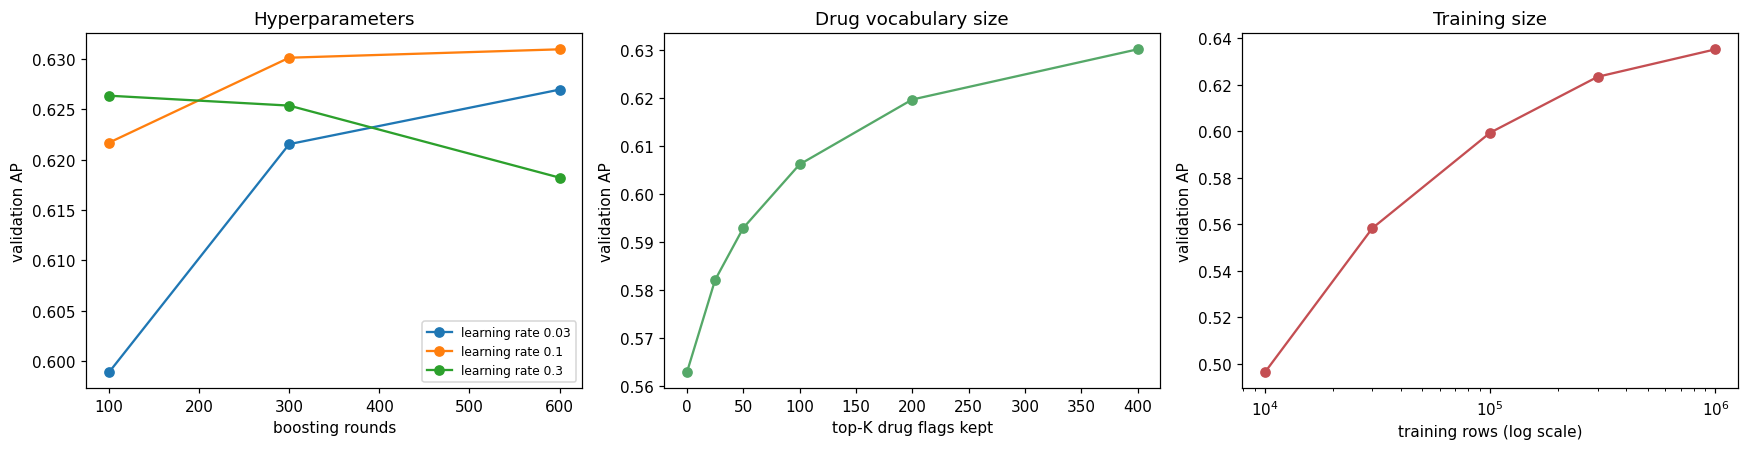

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
hp = sensitivity.query("experiment == 'learning rate x rounds'")
for lr, part in hp.groupby("learning_rate"):
    axes[0].plot(part["max_iter"], part["val_avg_precision"], marker="o", label=f"learning rate {lr}")
axes[0].set(xlabel="boosting rounds", ylabel="validation AP", title="Hyperparameters")
axes[0].legend(fontsize=8)
vocab = sensitivity.query("experiment == 'drug vocabulary'")
axes[1].plot(vocab["top_k_drugs"], vocab["val_avg_precision"], marker="o", color="#55A868")
axes[1].set(xlabel="top-K drug flags kept", ylabel="validation AP", title="Drug vocabulary size")
size = sensitivity.query("experiment == 'training size'")
axes[2].plot(size["n_train"], size["val_avg_precision"], marker="o", color="#C44E52")
axes[2].set_xscale("log")
axes[2].set(xlabel="training rows (log scale)", ylabel="validation AP", title="Training size")
fig.tight_layout()
save_fig(fig, "sup_sensitivity")
plt.show()

## 9. Trade-offs

**Precision vs recall.** The threshold decides how many cases a reviewer must read. The table shows what each
operating point means on the test quarters, using the calibrated best model.

**Speed vs accuracy.** Fit time on 1M rows against test AP, per family (from section 5).

**Stability over time.** AP per quarter across validation and test: does the model degrade as it ages?

In [13]:
p_cal = {"val": calibrator.predict(val_probs[BEST]), "test": p_test_cal}
operating_points = []
for target_recall in (0.5, 0.7, 0.8, 0.9, 0.95):
    precision, recall, thresholds = precision_recall_curve(y["val"], p_cal["val"])
    idx = np.flatnonzero(recall[:-1] >= target_recall)[-1]  # highest threshold that still reaches the recall
    row = threshold_metrics(y["test"], p_cal["test"], thresholds[idx])
    operating_points.append({"target_recall_on_val": target_recall, **row})
operating_points = pd.DataFrame(operating_points)
operating_points["cases_to_review_per_1000"] = operating_points["alert_rate"] * 1000
operating_points.to_csv(TABLE_DIR / "supervised_operating_points.csv", index=False)
display(operating_points[["target_recall_on_val", "threshold", "precision", "recall", "f1", "alert_rate",
                          "cases_to_review_per_1000"]].round(3))

split_quarters = pd.read_parquet(FEATURES_DIR / "split.parquet", columns=["safetyreportid", "quarter"])
quarter_of = split_quarters.set_index("safetyreportid")["quarter"]
drift_rows = []
for split in ("val", "test"):
    q = quarter_of.reindex(ids[split]).to_numpy()
    for quarter in sorted(set(q)):
        mask = q == quarter
        drift_rows.append({"quarter": quarter, "split": split, "n": int(mask.sum()), "positive_rate": y[split][mask].mean(),
                           **{f"ap_{f}": average_precision_score(y[split][mask], (val_probs if split == "val" else test_probs)[f][mask])
                              for f in ("logistic regression", BEST)}})
drift = pd.DataFrame(drift_rows)
drift.to_csv(TABLE_DIR / "supervised_ap_by_quarter.csv", index=False)
display(drift.round(4))

,target_recall_on_val,threshold,precision,recall,f1,alert_rate,cases_to_review_per_1000
0,0.50,0.474,0.596,0.503,0.546,0.221,220.508
1,0.70,0.348,0.511,0.718,0.597,0.367,367.498
2,0.80,0.256,0.466,0.810,0.592,0.454,454.209
3,0.90,0.179,0.413,0.901,0.567,0.570,570.293
4,0.95,0.099,0.371,0.948,0.533,0.668,668.298


,quarter,split,n,positive_rate,ap_logistic regression,ap_gradient boosting
0,2025Q1,val,312038,0.2622,0.5571,0.6512
1,2025Q2,val,314323,0.2577,0.5445,0.6176
2,2025Q3,test,377842,0.2693,0.5429,0.6141
3,2025Q4,test,325414,0.2674,0.5383,0.5961
4,2026Q1,test,354634,0.2641,0.5430,0.6178
5,2026Q2,test,413809,0.2475,0.5157,0.5803


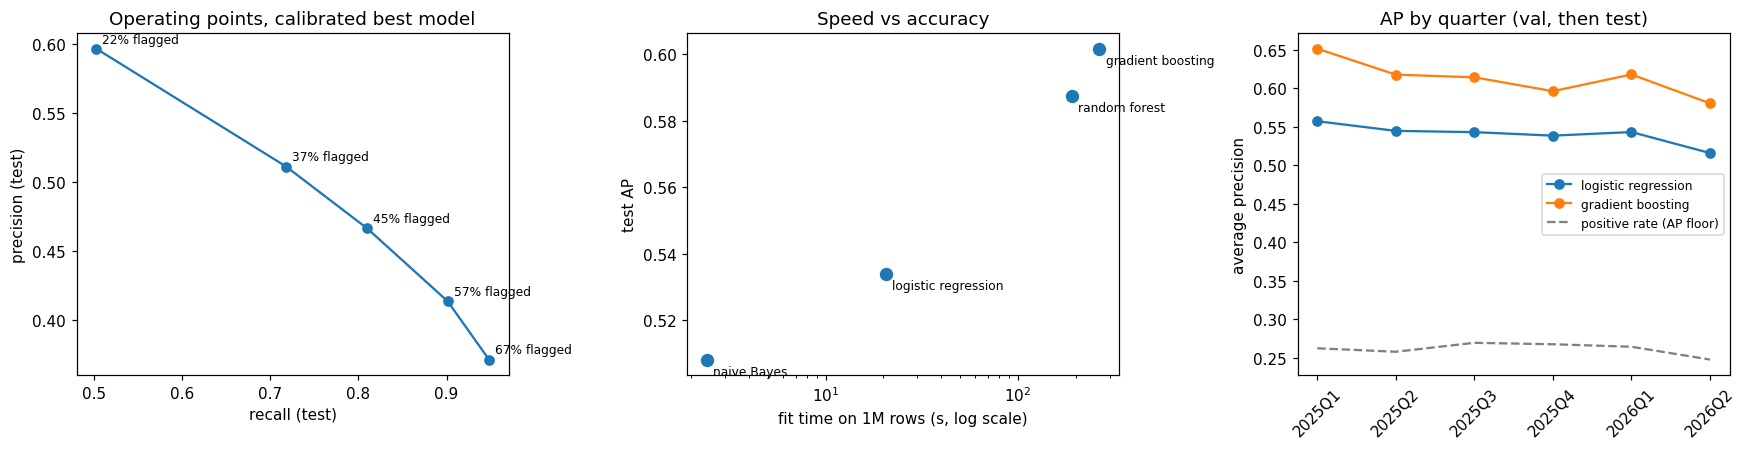

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(operating_points["recall"], operating_points["precision"], marker="o")
for _, r in operating_points.iterrows():
    axes[0].annotate(f"{r['alert_rate']:.0%} flagged", (r["recall"], r["precision"]), fontsize=8,
                     textcoords="offset points", xytext=(4, 4))
axes[0].set(xlabel="recall (test)", ylabel="precision (test)", title="Operating points, calibrated best model")
speed = final_results.query("split == 'test' and family != 'prior'")
axes[1].scatter(speed["fit_seconds"], speed["avg_precision"], s=60)
for _, r in speed.iterrows():
    axes[1].annotate(r["family"], (r["fit_seconds"], r["avg_precision"]), fontsize=8, textcoords="offset points", xytext=(4, -10))
axes[1].set_xscale("log")
axes[1].set(xlabel="fit time on 1M rows (s, log scale)", ylabel="test AP", title="Speed vs accuracy")
for family in ("logistic regression", BEST):
    axes[2].plot(drift["quarter"].astype(str), drift[f"ap_{family}"], marker="o", label=family)
axes[2].plot(drift["quarter"].astype(str), drift["positive_rate"], ls="--", color="grey", label="positive rate (AP floor)")
axes[2].set(ylabel="average precision", title="AP by quarter (val, then test)")
axes[2].tick_params(axis="x", rotation=45)
axes[2].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "sup_tradeoffs")
plt.show()

## 10. Failure analysis

Errors on the **test quarters** at the validation-chosen F1 threshold. We first measure where errors concentrate,
then read individual cases. To explain a failure we also look at the case's reaction terms and its full
ingredient list; these are **not** model inputs (reactions leak the target), only a way to understand the case.

In [15]:
test_cases = pd.read_parquet(FEATURES_DIR / "case_features.parquet").query("split == 'test'").reset_index(drop=True)
assert (test_cases["safetyreportid"].to_numpy() == ids["test"]).all(), "row order differs from X_test"
threshold = final_results.query("family == @BEST and split == 'test'")["threshold"].iloc[0]
test_cases["p"] = test_probs[BEST]
test_cases["pred"] = test_cases["p"] >= threshold
test_cases["error"] = np.select([test_cases["pred"] & (test_cases["y"] == 0), ~test_cases["pred"] & (test_cases["y"] == 1)],
                                ["false positive", "false negative"], "correct")
test_cases["no_known_drug"] = test_cases["n_other_ingredients"] == test_cases["n_suspect_ingredients"]
test_cases["sparse_patient"] = (test_cases["age_missing"] == 1) & (test_cases["sex"] == "missing")

segments = {
    "all test cases": np.ones(len(test_cases), bool),
    "no top-400 drug on the case": test_cases["no_known_drug"],
    "age and sex both missing": test_cases["sparse_patient"],
    "consumer reporter": test_cases["reporter"] == "consumer",
    "lawyer reporter": test_cases["reporter"] == "lawyer",
    "health professional, outside US": test_cases["reporter"].isin(["physician", "pharmacist", "other_hcp"]) & (test_cases["is_us"] == 0),
    "single drug on the case": test_cases["n_drugs"] == 1,
    "10+ drugs on the case": test_cases["n_drugs"] >= 10,
}
seg_rows = []
for name, mask in segments.items():
    part = test_cases[np.asarray(mask)]
    seg_rows.append({"segment": name, "n": len(part), "share_of_test": len(part) / len(test_cases),
                     "positive_rate": part["y"].mean(), "avg_precision": average_precision_score(part["y"], part["p"]),
                     "false_negative_rate": ((part["error"] == "false negative").sum() / max((part["y"] == 1).sum(), 1)),
                     "false_positive_rate": ((part["error"] == "false positive").sum() / max((part["y"] == 0).sum(), 1))})
segment_errors = pd.DataFrame(seg_rows)
segment_errors.to_csv(TABLE_DIR / "supervised_error_segments.csv", index=False)
display(segment_errors.round(3))

,segment,n,share_of_test,positive_rate,avg_precision,false_negative_rate,false_positive_rate
0,all test cases,1471699,1.000,0.262,0.602,0.262,0.262
1,no top-400 drug on the case,351772,0.239,0.234,0.489,0.313,0.289
2,age and sex both missing,208451,0.142,0.161,0.425,0.447,0.160
3,consumer reporter,752314,0.511,0.189,0.532,0.426,0.141
4,lawyer reporter,16295,0.011,0.126,0.389,0.768,0.033
5,"health professional, outside US",389149,0.264,0.450,0.643,0.093,0.734
6,single drug on the case,707543,0.481,0.199,0.551,0.352,0.174
7,10+ drugs on the case,143799,0.098,0.439,0.705,0.143,0.529


Now individual cases. We pick, by rule rather than by hand:

1. the most confident **false negative with no top-400 drug** (the model has only demographics to go on);
2. the most confident **false negative with a known drug** (the drug looked safe, the case was not);
3. the most confident **false positive** (everything looked serious, the label says it was not);
4. a confident **false negative from a consumer report with no age or sex**;
5. the most confident **false positive among cases with 5 or fewer drugs** (to look past very large reports).

Each example is a different case.

In [16]:
ingredients_all = pq.read_table(CLEAN_DIR / "case_ingredients", columns=["safetyreportid", "ingredient"]).to_pandas()
reactions_all = pq.read_table(CLEAN_DIR / "case_reactions", columns=["safetyreportid", "reaction_pt"]).to_pandas()
reports_clean = pd.read_parquet(CLEAN_DIR / "reports_clean.parquet",
                                columns=["safetyreportid", "quarter", "death", "hospitalization", "is_serious", "expedited"])

fn, fp = test_cases[test_cases["error"] == "false negative"], test_cases[test_cases["error"] == "false positive"]
rules = {
    "A. false negative, no known drug": lambda: fn[fn["no_known_drug"]].nsmallest(1, "p"),
    "B. false negative, known drug": lambda: fn[~fn["no_known_drug"]].nsmallest(1, "p"),
    "C. false positive": lambda: fp.nlargest(1, "p"),
    "D. false negative, consumer, no age/sex": lambda: fn[(fn["reporter"] == "consumer") & fn["sparse_patient"]].nsmallest(1, "p"),
    "E. false positive, 5 or fewer drugs": lambda: fp[fp["n_drugs"] <= 5].nlargest(1, "p"),
}
example_rows, used = [], set()
for label, rule in rules.items():
    fn, fp = fn[~fn["safetyreportid"].isin(used)], fp[~fp["safetyreportid"].isin(used)]  # each example a different case
    row = rule().iloc[0]
    used.add(row["safetyreportid"])
    case_id = row["safetyreportid"]
    info = reports_clean.loc[reports_clean["safetyreportid"] == case_id].iloc[0]
    drugs = ingredients_all.loc[ingredients_all["safetyreportid"] == case_id, "ingredient"].tolist()
    rxns = reactions_all.loc[reactions_all["safetyreportid"] == case_id, "reaction_pt"].tolist()
    example_rows.append({"example": label, "safetyreportid": case_id, "quarter": info["quarter"], "p_serious": row["p"],
                         "label": "serious" if row["y"] == 1 else "not serious", "death": info["death"],
                         "hospitalization": info["hospitalization"], "reporter": row["reporter"], "country": row["country"],
                         "sex": row["sex"], "age": row["age_years"], "n_drugs": row["n_drugs"],
                         "suspect_ingredients": " | ".join(drugs[:6]), "reactions": " | ".join(rxns[:8])})
failure_examples = pd.DataFrame(example_rows)
failure_examples.to_csv(TABLE_DIR / "supervised_failure_examples.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(failure_examples.T)

,0,1,2,3,4
example,"A. false negative, no known drug","B. false negative, known drug",C. false positive,"D. false negative, consumer, no age/sex","E. false positive, 5 or fewer drugs"
safetyreportid,25957795,26782616,26901066,24117356,25824268
quarter,2025Q4,2026Q2,2026Q2,2025Q3,2025Q3
p_serious,0.03946,0.003023,0.998244,0.003751,0.990555
label,serious,serious,not serious,serious,not serious
death,False,False,False,True,False
hospitalization,True,True,False,False,False
reporter,consumer,consumer,other_hcp,consumer,physician
country,US,US,CA,US,US
sex,missing,missing,missing,missing,male


**How often does the reaction list contradict the label?** If a "not serious" case lists a reaction that is
almost always serious (notebook 3: `DEATH`, sepsis, cardiac arrest...), the label itself may be wrong.
We measure this for confident false positives versus all true negatives.

In [17]:
always_serious = {"DEATH", "COMPLETED SUICIDE", "CARDIAC ARREST", "SEPSIS", "SEPTIC SHOCK", "RESPIRATORY FAILURE",
                  "PNEUMONIA", "ACUTE KIDNEY INJURY", "CEREBROVASCULAR ACCIDENT", "MYOCARDIAL INFARCTION"}
flag_ids = set(reactions_all.loc[reactions_all["reaction_pt"].isin(always_serious), "safetyreportid"])
confident_fp = fp[fp["p"] >= fp["p"].quantile(0.9)]
true_neg = test_cases[(test_cases["y"] == 0) & ~test_cases["pred"]]
label_noise = pd.DataFrame({
    "group": ["confident false positives (top 10% of p)", "true negatives"],
    "n": [len(confident_fp), len(true_neg)],
    "share_listing_a_severe_reaction": [confident_fp["safetyreportid"].isin(flag_ids).mean(),
                                        true_neg["safetyreportid"].isin(flag_ids).mean()],
})
label_noise.to_csv(TABLE_DIR / "supervised_label_noise_check.csv", index=False)
display(label_noise.round(3))

,group,n,share_listing_a_severe_reaction
0,confident false positives (top 10% of p),28472,0.049
1,true negatives,802202,0.012


## 11. Save the scoring model

Notebook 7 applies this file to new cases: it holds the best model, the isotonic calibrator fit on validation,
and the F1 threshold chosen on validation.

In [18]:
joblib.dump({"model": best_model, "family": BEST, "calibrator": calibrator, "threshold": threshold,
             "calibrated_threshold": float(calibrator.predict([threshold])[0]), "feature_names": feature_names},
            MODEL_DIR / "serious_outcome_model.joblib")
pd.DataFrame({"safetyreportid": ids["test"], "y": y["test"], "p_raw": test_probs[BEST], "p_calibrated": p_test_cal}) \
    .to_parquet(MODEL_DIR / "test_predictions.parquet", index=False)
print("saved", MODEL_DIR / "serious_outcome_model.joblib")

saved /Users/suvidhinikhil/Data science projects/Milestone 2 projects/FAERS_Milestone2_Final/models/serious_outcome_model.joblib


## Summary

The numbers in the written report are read from the tables saved above (`reports/tables/supervised_*.csv`).

- **Best family: histogram gradient boosting.** Test-year AP 0.602 / ROC AUC 0.818, vs random forest 0.587 / 0.811,
  logistic regression 0.534 / 0.788, naive Bayes 0.508 / 0.778 and the prior 0.262. The 5-fold CV ranking is the same,
  with fold spreads (sd at most 0.004) far smaller than the gaps between families.
- **What drives it:** the drug flags (AP drop 0.158 when shuffled) and the report's origin (US vs non-US 0.072,
  reporter 0.046, report type 0.044). Removing the drug group or the report group costs about 0.065 AP each when
  retrained; patient fields add about 0.02.
- **Sensitivity:** a plateau over learning rate and rounds; AP keeps rising with more drug flags (about +0.01 per
  doubling) and with more training rows (0.50 at 10k to 0.635 at 1M); seed-to-seed spread is 0.0002.
- **Drift:** AP falls from 0.651 (2025Q1) to 0.580 (2026Q2) as new drugs fall outside the training vocabulary.
- **Failures:** sparse, uninformative or contradictory consumer reports (false negatives); outcomes that are serious
  by another criterion, such as congenital anomalies (false positives); and some label noise: confident false
  positives list a nearly-always-serious reaction four times as often as true negatives (4.9% vs 1.2%).